Import Libraries

In [ ]:

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Dataset
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Visualization
import matplotlib.pyplot as plt
import numpy as np

# Check GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)


PyTorch version: 2.14.1+cu130
Device: cuda


Load MNIST Dataset

In [ ]:

# Image preprocessing
transform = transforms.ToTensor()

# Download training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 10.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 351kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.53MB/s]

Training samples: 60000
Testing samples: 10000


Visualise Data

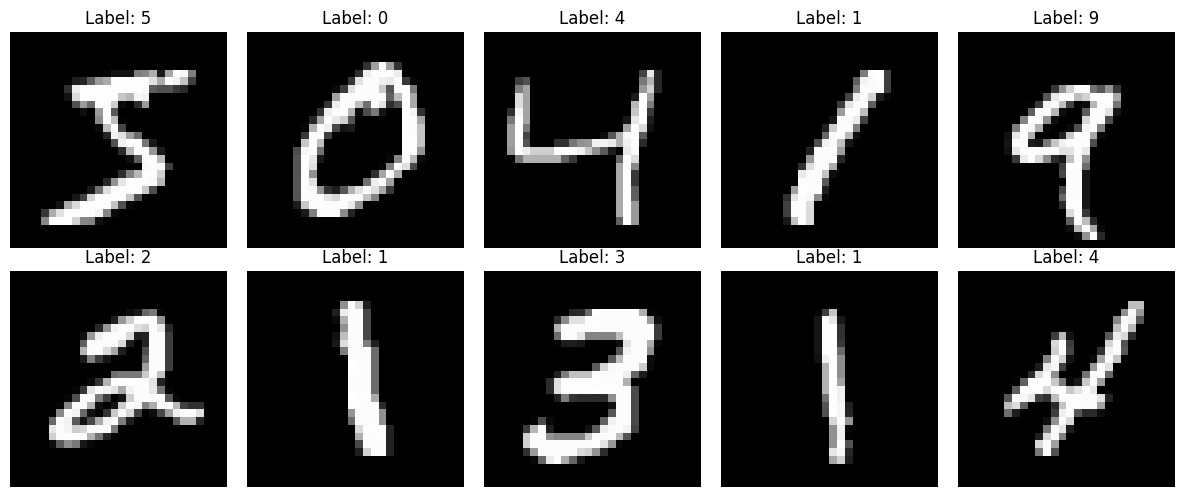

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Prepare Dataloader

In [ ]:

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Inspect one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


CNN

In [ ]:

class DigitCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)

        # Pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model = DigitCNN().to(device)

print(model)


DigitCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


Training Loop

In [ ]:

# 1. Initialize model
model = DigitCNN().to(device)

# 2. Define loss function
criterion = nn.CrossEntropyLoss()

# 3. Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# 4. Training settings
epochs = 5

# Store training losses
train_losses = []

# 5. Training loop
for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {epoch_loss:.4f}"
    )

print("Training completed!")


Epoch [1/5], Loss: 0.2151
Epoch [2/5], Loss: 0.0609
Epoch [3/5], Loss: 0.0415
Epoch [4/5], Loss: 0.0325
Epoch [5/5], Loss: 0.0250
Training completed!


Training Loss Visualisation

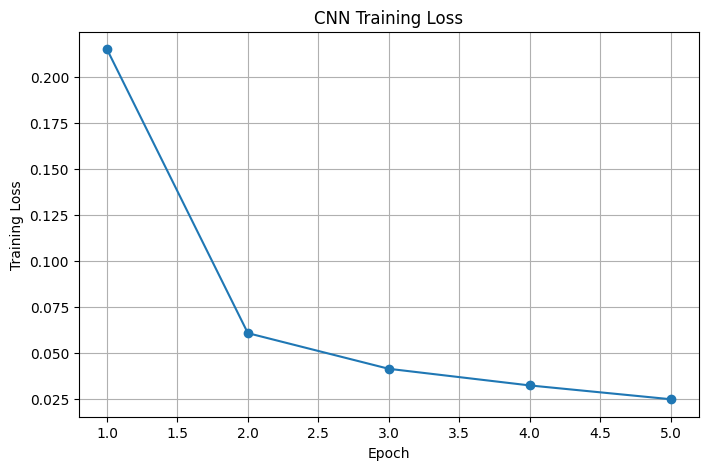

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")
plt.grid(True)

plt.show()


Evaluation of the Model

In [ ]:

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predicted = torch.argmax(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")


Test Accuracy: 98.77%


Visualisation of Predictions

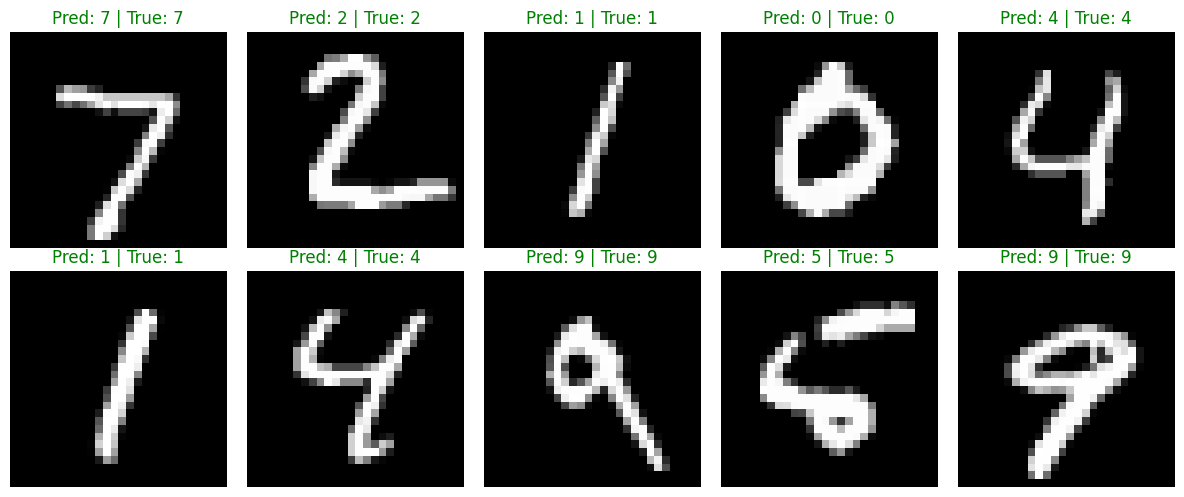

In [ ]:

images, labels = next(iter(test_loader))

images = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)
    predictions = torch.argmax(outputs, dim=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    image = images[i].cpu().squeeze()
    prediction = predictions[i].item()
    actual = labels[i].item()

    ax.imshow(image, cmap="gray")

    color = "green" if prediction == actual else "red"

    ax.set_title(
        f"Pred: {prediction} | True: {actual}",
        color=color
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


Save Trained Model Weights

In [ ]:
# Save trained model weights
torch.save(model.state_dict(), "digit_cnn.pth")

print("Model saved successfully!")

Model saved successfully!


Install Appliacation Dependencies

In [ ]:
!pip install -q streamlit streamlit-drawable-canvas
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴

# Application

In [ ]:

%%writefile app.py

import streamlit as st
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from PIL import Image
from streamlit_drawable_canvas import st_canvas


# ==========================================
# 1. Streamlit page configuration
# ==========================================

st.set_page_config(
    page_title="Handwritten Digit Recognizer",
    page_icon="🔢",
    layout="centered"
)


# ==========================================
# 2. CNN Model
# ==========================================

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# ==========================================
# 3. Load trained model
# ==========================================

@st.cache_resource
def load_model():
    model = DigitCNN()

    model.load_state_dict(
        torch.load("digit_cnn.pth", map_location="cpu")
    )

    model.eval()

    return model


model = load_model()


# ==========================================
# 4. App title and description
# ==========================================

st.title("🔢 Handwritten Digit Recognizer")

st.write(
    "Draw a digit from 0 to 9 in the canvas below, "
    "and let the CNN model predict what you wrote!"
)


# ==========================================
# 5. Drawing canvas
# ==========================================

st.subheader("Draw your digit here")

canvas_result = st_canvas(
    fill_color="rgba(255, 255, 255, 1)",
    stroke_width=18,
    stroke_color="#FFFFFF",
    background_color="#000000",
    height=280,
    width=280,
    drawing_mode="freedraw",
    return_image_data=True,
    key="digit_canvas"
)


# ==========================================
# 6. Prediction
# ==========================================

if st.button("Predict", type="primary"):

    if canvas_result.image_data is None:
        st.warning("Please draw a digit first.")

    else:
        # Convert canvas image to NumPy array
        img_array = canvas_result.image_data.astype(np.uint8)

        # Convert RGBA image to grayscale
        img = Image.fromarray(img_array).convert("L")

        # Resize image to MNIST dimensions (28 x 28)
        img = img.resize((28, 28))

        # Convert image to NumPy array
        img_array = np.array(img).astype(np.float32)

        # Normalize pixel values to [0, 1]
        img_array /= 255.0

        # Check whether the canvas is blank
        if img_array.max() < 0.05:
            st.warning("Please draw a digit before predicting.")

        else:
            # Convert to PyTorch tensor
            # Shape: [1, 1, 28, 28]
            input_tensor = torch.tensor(
                img_array,
                dtype=torch.float32
            ).unsqueeze(0).unsqueeze(0)

            # Run model inference
            with torch.no_grad():
                outputs = model(input_tensor)

                probabilities = F.softmax(outputs, dim=1)

                predicted_digit = torch.argmax(
                    probabilities, dim=1
                ).item()

            # ==========================================
            # 7. Display prediction results
            # ==========================================

            confidence = probabilities[0][predicted_digit].item()

            st.markdown(
                f"""
                <div style="font-size: 32px; font-weight: bold; color: #28a745;">
                    Predicted Digit: {predicted_digit}
                </div>
                """,
                unsafe_allow_html=True
            )

            st.metric(
                label="Confidence",
                value=f"{confidence * 100:.2f}%"
            )

            # Display all class probabilities
            st.subheader("Class Probabilities")

            prob_array = probabilities[0].numpy()

            for digit, prob in enumerate(prob_array):
                st.write(f"Digit {digit}: {prob * 100:.2f}%")

                st.progress(float(prob))



Overwriting app.py


In [ ]:
!pip install -q streamlit streamlit-drawable-canvas
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧
changed 22 packages in 1s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧

In [ ]:
import os

print("Model exists:", os.path.exists("digit_cnn.pth"))
print("App exists:", os.path.exists("app.py"))

Model exists: True
App exists: True


In [ ]:
import subprocess
import time

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("Process ID:", process.pid)
print("Process running:", process.poll() is None)

Process ID: 1172
Process running: True


In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")

print("Your app URL:", url)

Your app URL: https://8501-gpu-t4-s-euw4a0-3knopn4309znq-a.europe-west4.prod.r.colab.dev
